In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

DATA_DIR= Path("../data/raw")

Chargement et valeurs manquantes

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv", parse_dates=["Date"])
features = pd.read_csv(DATA_DIR / "features.csv", parse_dates=["Date"])
stores = pd.read_csv(DATA_DIR / "stores.csv")

print (train.shape, features.shape, stores.shape)
features.isna().mean().sort_values(ascending=False)

(421570, 5) (8190, 12) (45, 3)


MarkDown2      0.64
MarkDown4      0.58
MarkDown3      0.56
MarkDown1      0.51
MarkDown5      0.51
CPI            0.07
Unemployment   0.07
Store          0.00
Fuel_Price     0.00
Temperature    0.00
Date           0.00
IsHoliday      0.00
dtype: float64

Fusion et nettoyage

In [3]:
features = features.drop(columns=["IsHoliday"])

df = (train
      .merge(features, on= ["Store", "Date"], how="left")
      .merge(stores, on="Store", how="left"))

markdown_cols=[c for c in df.columns if c.startswith("MarkDown")]
df[markdown_cols] = df[markdown_cols].fillna(0)

df = df.sort_values(["Store", "Dept", "Date"]).reset_index(drop=True)


Controle qualité

In [4]:
df.info()
display(df.describe().T)
print("Doublons (Store, Dept, Date) :", df.duplicated(subset=["Store", "Dept", "Date"]).sum())
print ("Vente négatives :", (df["Weekly_Sales"]<0).sum())

<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Store         421570 non-null  int64         
 1   Dept          421570 non-null  int64         
 2   Date          421570 non-null  datetime64[us]
 3   Weekly_Sales  421570 non-null  float64       
 4   IsHoliday     421570 non-null  bool          
 5   Temperature   421570 non-null  float64       
 6   Fuel_Price    421570 non-null  float64       
 7   MarkDown1     421570 non-null  float64       
 8   MarkDown2     421570 non-null  float64       
 9   MarkDown3     421570 non-null  float64       
 10  MarkDown4     421570 non-null  float64       
 11  MarkDown5     421570 non-null  float64       
 12  CPI           421570 non-null  float64       
 13  Unemployment  421570 non-null  float64       
 14  Type          421570 non-null  str           
 15  Size          421570 non-nul

,count,mean,min,25%,50%,75%,max,std
Store,"421,570.00",22.20,1.00,11.00,22.00,33.00,45.00,12.79
Dept,"421,570.00",44.26,1.00,18.00,37.00,74.00,99.00,30.49
Date,421570,2011-06-18 08:30:31.963375,2010-02-05 00:00:00,2010-10-08 00:00:00,2011-06-17 00:00:00,2012-02-24 00:00:00,2012-10-26 00:00:00,NaN
Weekly_Sales,"421,570.00","15,981.26","-4,988.94","2,079.65","7,612.03","20,205.85","693,099.36","22,711.18"
Temperature,"421,570.00",60.09,-2.06,46.68,62.09,74.28,100.14,18.45
Fuel_Price,"421,570.00",3.36,2.47,2.93,3.45,3.74,4.47,0.46
MarkDown1,"421,570.00","2,590.07",0.00,0.00,0.00,"2,809.05","88,646.76","6,052.39"
MarkDown2,"421,570.00",879.97,-265.76,0.00,0.00,2.20,"104,519.54","5,084.54"
MarkDown3,"421,570.00",468.09,-29.10,0.00,0.00,4.54,"141,630.61","5,528.87"
MarkDown4,"421,570.00","1,083.13",0.00,0.00,0.00,425.29,"67,474.85","3,894.53"


Doublons (Store, Dept, Date) : 0
Vente négatives : 1285


In [6]:
negative_sales = df[df["Weekly_Sales"] < 0]
display(negative_sales.head(10))

print("Pourcentage :", len(negative_sales) / len(df) * 100)

,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size
846,1,6,2012-08-10,-139.65,False,85.05,3.49,"11,436.22",245.00,6.85,"6,964.26","4,836.22",221.96,6.91,A,151315
2384,1,18,2012-05-04,-1.27,False,75.55,3.75,"21,290.13",0.00,69.89,"4,977.35","3,261.04",221.67,7.14,A,151315
6048,1,47,2010-02-19,-863.00,False,39.93,2.51,0.00,0.00,0.00,0.00,0.00,211.29,8.11,A,151315
6049,1,47,2010-03-12,-698.00,False,57.79,2.67,0.00,0.00,0.00,0.00,0.00,211.38,8.11,A,151315
6051,1,47,2010-10-08,-58.00,False,63.93,2.63,0.00,0.00,0.00,0.00,0.00,211.75,7.84,A,151315
6056,1,47,2011-04-08,-298.00,False,67.84,3.62,0.00,0.00,0.00,0.00,0.00,215.07,7.68,A,151315
6057,1,47,2011-07-08,-198.00,False,85.83,3.48,0.00,0.00,0.00,0.00,0.00,215.28,7.96,A,151315
6061,1,47,2011-10-14,-498.00,False,71.74,3.27,0.00,0.00,0.00,0.00,0.00,217.36,7.87,A,151315
6062,1,47,2011-12-23,-498.00,False,47.96,3.11,"2,725.36",40.48,634.70,24.90,"2,739.43",219.36,7.87,A,151315
6063,1,47,2012-02-17,-198.00,False,45.32,3.51,"9,873.33","11,062.27",9.80,"8,409.31","3,402.66",220.43,7.35,A,151315


Pourcentage : 0.30481296107408024


In [7]:
display(
    negative_sales.groupby("Dept")["Weekly_Sales"]
    .count()
    .sort_values(ascending=False)
    .head(10)
)

Dept
47    254
18    180
54    146
19     87
94     77
80     68
49     67
59     44
72     34
78     33
Name: Weekly_Sales, dtype: int64

Traitement des ventes négatives

L'analyse du dataset révèle 1 285 observations avec des valeurs négatives dans Weekly_Sales. Ces valeurs peuvent correspondre à des retours de produits ou à des ajustements comptables.

J'ai choisi de conserver ces observations plutôt que de les supprimer ou de les remplacer par 0. En effet, remplacer les ventes négatives par 0 modifierait artificiellement les données et ferait perdre l'information liée aux retours ou ajustements.

Les ventes négatives seront donc conservées pour la suite de l'analyse. Leur impact pourra être vérifié lors de l'analyse exploratoire et de l'évaluation du modèle.

Distribution des ventes

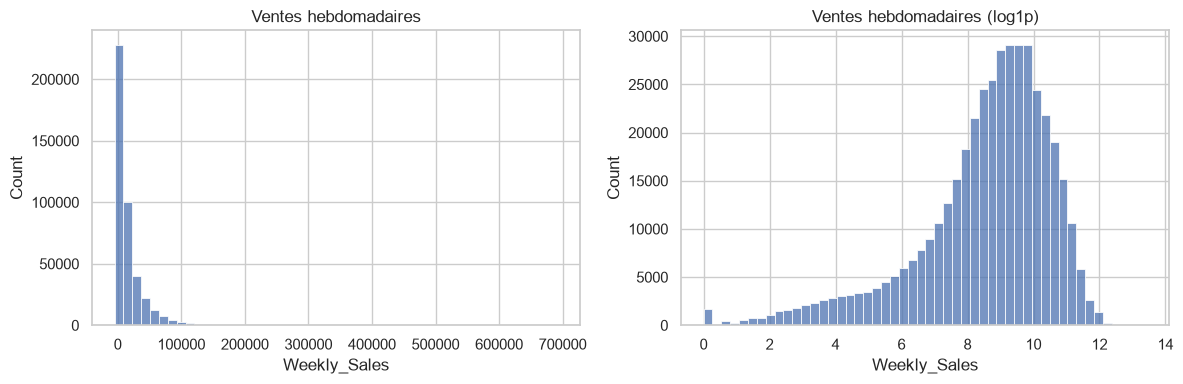

In [8]:
fig , axes = plt.subplots(1,2, figsize=(12,4))

sns.histplot(df["Weekly_Sales"], bins=50, ax=axes[0])
axes[0].set_title("Ventes hebdomadaires")

sns.histplot(np.log1p(df["Weekly_Sales"].clip(lower=0)), bins=50, ax=axes[1])
axes[1].set_title("Ventes hebdomadaires (log1p)")

plt.tight_layout()
plt.show()

Tendance globale et jours fériés

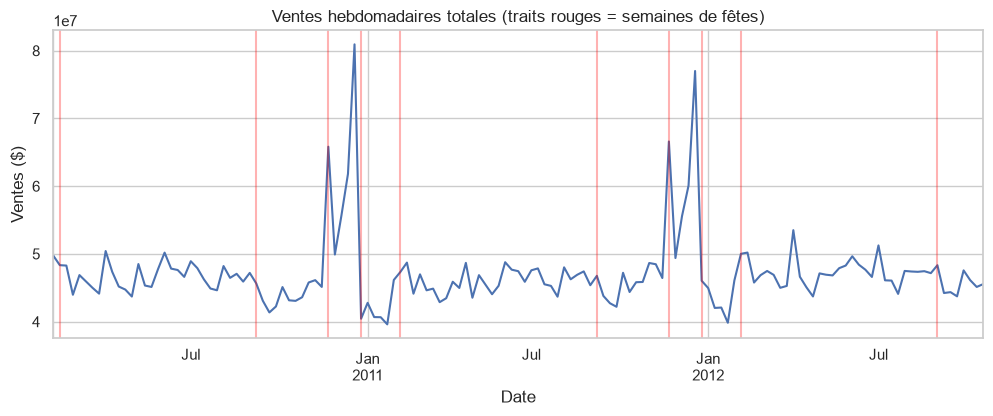

In [9]:
weekly_total = df.groupby("Date")["Weekly_Sales"].sum()

ax = weekly_total.plot(figsize=(12, 4))
for d in df.loc[df["IsHoliday"], "Date"].unique():
    ax.axvline(d, color="red", alpha=0.3)

ax.set_title("Ventes hebdomadaires totales (traits rouges = semaines de fêtes)")
ax.set_ylabel("Ventes ($)")
plt.show()